In [3]:
import pandas as pnd
import numpy as np
from matplotlib import pyplot as plt
from sklearn.model_selection import train_test_split
import tensorflow as tf
import keras

tf.config.set_visible_devices([], 'GPU')

#Définition de la longueur et de la largeur de l'image
LONGUEUR_IMAGE = 28
LARGEUR_IMAGE = 28

#Chargement des images
observations_entrainement = pnd.read_csv('../data/fashion-mnist_train.csv')

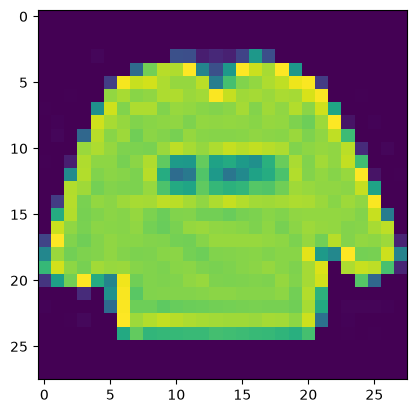

In [4]:
#On exclut la remière colonne (les labels) pour constituer un tableau de pixels
X = np.array(observations_entrainement.iloc[:, 1:])

premiereImage = X[0]
premiereImage = premiereImage.reshape([LONGUEUR_IMAGE,LARGEUR_IMAGE])
plt.imshow(premiereImage)
plt.show()

In [5]:
#On crée des catégories à l'aide du module Keras
y = keras.utils.to_categorical(np.array(observations_entrainement.iloc[:,0]))
#Réparation des données d'entrainement en données d'apprentissage et données de validation
#80% de donnée d'apprentissage et 20% de donnée de validation
X_apprentissage, X_validation,y_apprentissage, y_validation = train_test_split(X, y, test_size=0.2, random_state=13)

In [6]:
#On redimensionne le simages au format 28*28 et on réalise un scaling sur les données des pixels
X_apprentissage = X_apprentissage.reshape(X_apprentissage.shape[0], LARGEUR_IMAGE, LONGUEUR_IMAGE, 1)

X_apprentissage = X_apprentissage.astype('float32')
X_apprentissage /= 255

X_validation = X_validation.reshape(X_validation.shape[0], LARGEUR_IMAGE, LONGUEUR_IMAGE, 1)

X_validation = X_validation.astype('float32')
X_validation /= 255

In [7]:
#Preparation des données de tests
observations_test = pnd.read_csv('../data/fashion-mnist_test.csv')
X_test = np.array(observations_test.iloc[:, 1:])
y_test = tf.keras.utils.to_categorical(np.array(observations_test.iloc[:, 0]))
X_test = X_test.reshape(X_test.shape[0], LARGEUR_IMAGE, LONGUEUR_IMAGE, 1)
X_test = X_test.astype('float32')
X_test /= 255

In [8]:
from keras.models import Sequential
from keras.layers import Dense, Dropout, Flatten, Input
from keras.layers import Conv2D, MaxPooling2D

# On spécifie les dimensions de l'image d'entrée
dimentionImage = (LARGEUR_IMAGE, LONGUEUR_IMAGE, 1)

# On crée le réseau de neurones couche par couche
reseauNeurone1Convolution = Sequential()

# Ajout de la couche d'entrée
reseauNeurone1Convolution.add(Input(shape=dimentionImage))

#1- Ajout de la couche de convolution comportant
# 32 filtres de de taille 3x3 (Kernel) parcourant l'image
# Une fonction d'activation de type ReLU (Rectified Linear Activation)
# Une image d'entrée de 28px * 28 px 
reseauNeurone1Convolution.add(Conv2D(32, 
                                     kernel_size=(3, 3), 
                                     activation='relu'))

#2- Définition de la fonction de pooling avec une fenêtre de 2px sur 2 px
reseauNeurone1Convolution.add(MaxPooling2D(pool_size=(2, 2)))

#3- Ajout d'une fonction d'ignorance
reseauNeurone1Convolution.add(Dropout(0.2))

#5 - On transforme en une seule ligne
reseauNeurone1Convolution.add(Flatten())

#6 - Ajout d'un réseau de neurones composé de 128 neurones avec 
# une fonction d'activation de type ReLU
reseauNeurone1Convolution.add(Dense(128, activation='relu'))

#7 - Ajout d'un réseau de neurones composé de 10 neurones avec une 
# fonction d'activation de type softmax
reseauNeurone1Convolution.add(Dense(10, activation='softmax'))

In [9]:
reseauNeurone1Convolution.compile(loss=keras.losses.categorical_crossentropy, 
                                  optimizer=tf.keras.optimizers.Adam(), 
                                  metrics=['accuracy'])

In [10]:
historique_apprentissage = reseauNeurone1Convolution.fit(
    X_apprentissage, 
    y_apprentissage,
    batch_size=256,
    epochs=10,
    verbose=1,
    validation_data=(X_validation, y_validation))

Epoch 1/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 17s 72ms/step - accuracy: 0.8103 - loss: 0.5477 - val_accuracy: 0.8658 - val_loss: 0.3875
Epoch 2/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 11s 60ms/step - accuracy: 0.8740 - loss: 0.3604 - val_accuracy: 0.8775 - val_loss: 0.3483
Epoch 3/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 12s 63ms/step - accuracy: 0.8872 - loss: 0.3175 - val_accuracy: 0.8892 - val_loss: 0.3187
Epoch 4/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 13s 68ms/step - accuracy: 0.8975 - loss: 0.2900 - val_accuracy: 0.8967 - val_loss: 0.2990
Epoch 5/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 12s 63ms/step - accuracy: 0.9006 - loss: 0.2750 - val_accuracy: 0.8953 - val_loss: 0.2918
Epoch 6/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 12s 61ms/step - accuracy: 0.9066 - loss: 0.2572 - val_accuracy: 0.8988 - val_loss: 0.2807
Epoch 7/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 12s 63ms/step - accuracy: 0.9123 - loss: 0.2442 - val_accuracy: 0.9051 - val_loss: 0.2755
Epoch 8/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 12s 63ms/step - accuracy: 0.9167 - loss: 0.2325 - 

In [11]:
evaluation = reseauNeurone1Convolution.evaluate(X_test, y_test, verbose=0)
print('Erreur:', evaluation[0])
print('Précision:', evaluation[1])

Erreur: 0.24995197355747223
Précision: 0.9077000021934509


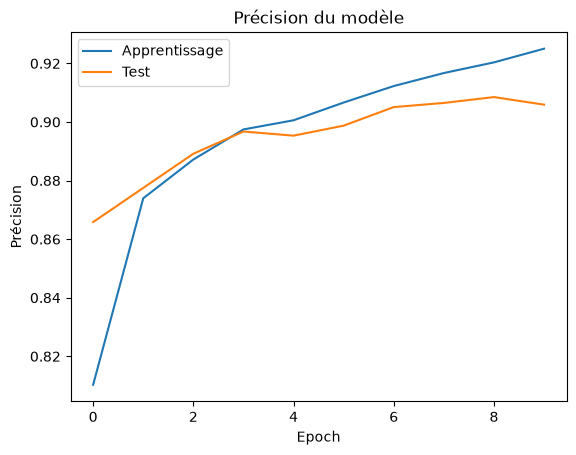

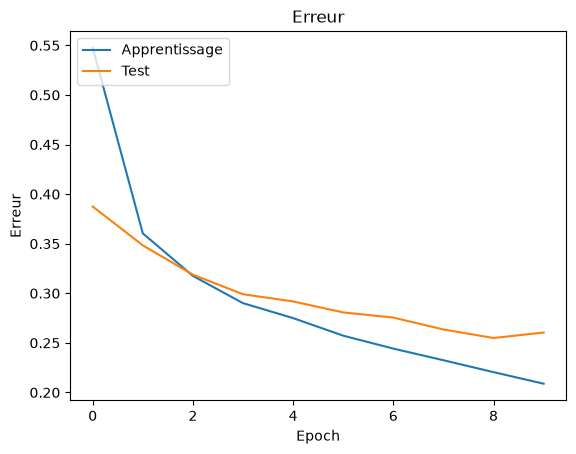

In [12]:
plt.plot(historique_apprentissage.history['accuracy'])
plt.plot(historique_apprentissage.history['val_accuracy'])
plt.title('Précision du modèle')
plt.ylabel('Précision')
plt.xlabel('Epoch')
plt.legend(['Apprentissage', 'Test'], loc='upper left')
plt.show()
# Plot training & validation loss values
plt.plot(historique_apprentissage.history['loss'])
plt.plot(historique_apprentissage.history['val_loss'])
plt.title('Erreur')
plt.ylabel('Erreur')
plt.xlabel('Epoch')
plt.legend(['Apprentissage', 'Test'], loc='upper left')
plt.show()

In [13]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

generateur_images = tf.keras.preprocessing.image.ImageDataGenerator(
    rotation_range=8,
    width_shift_range=0.08,
    shear_range=0.3,
    height_shift_range=0.08,
    zoom_range=0.08
)

In [14]:
nouvelles_images_apprentissage = generateur_images.flow(
    X_apprentissage, 
    y_apprentissage,
    batch_size=256)

nouvelles_images_validation = generateur_images.flow(
    X_validation, 
    y_validation,
    batch_size=256)

historique_apprentissage = reseauNeurone1Convolution.fit(
    nouvelles_images_apprentissage,
    steps_per_epoch=48000//256,
    epochs=50,
    validation_data=nouvelles_images_validation,
    validation_steps=12000//256,
    verbose=1 )

evaluation = reseauNeurone1Convolution.evaluate(X_test, y_test, verbose=0)

print('Erreur :', evaluation[0])
print('Précision:', evaluation[1])

Epoch 1/50


I0000 00:00:1793132383.443558   43982 generator_dataset_op.cc:213] Memory patch applied: M_TRIM_THRESHOLD=128 kb was set.


187/187 ━━━━━━━━━━━━━━━━━━━━ 35s 180ms/step - accuracy: 0.8247 - loss: 0.4657 - val_accuracy: 0.8327 - val_loss: 0.4323
Epoch 2/50
  1/187 ━━━━━━━━━━━━━━━━━━━━ 16s 89ms/step - accuracy: 0.8398 - loss: 0.4414

/workspaces/420-5G4-ML/agent/.venv/lib/python3.13/site-packages/keras/src/trainers/epoch_iterator.py:116: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


187/187 ━━━━━━━━━━━━━━━━━━━━ 5s 27ms/step - accuracy: 0.8398 - loss: 0.4414 - val_accuracy: 0.8359 - val_loss: 0.4331
Epoch 3/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 31s 163ms/step - accuracy: 0.8451 - loss: 0.4160 - val_accuracy: 0.8533 - val_loss: 0.3992
Epoch 4/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 5s 25ms/step - accuracy: 0.8203 - loss: 0.4246 - val_accuracy: 0.8502 - val_loss: 0.4028
Epoch 5/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 30s 160ms/step - accuracy: 0.8545 - loss: 0.3941 - val_accuracy: 0.8600 - val_loss: 0.3790
Epoch 6/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 5s 25ms/step - accuracy: 0.8906 - loss: 0.3365 - val_accuracy: 0.8621 - val_loss: 0.3708
Epoch 7/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 32s 167ms/step - accuracy: 0.8593 - loss: 0.3806 - val_accuracy: 0.8668 - val_loss: 0.3616
Epoch 8/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 5s 27ms/step - accuracy: 0.8594 - loss: 0.3705 - val_accuracy: 0.8658 - val_loss: 0.3624
Epoch 9/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 30s 157ms/step - accuracy: 0.8658 - loss: 0.3671 - val_accurac

In [15]:
#Sauvegarde du modèle
# Serialisation du modèle 
model_json = reseauNeurone1Convolution.to_json() 
with open("../modele/modele.json", "w") as json_file:
    json_file.write(model_json)
    
# Serialisation des poids
reseauNeurone1Convolution.save_weights("../modele/modele.weights.h5")
print("Modèle sauvegardé !")

Modèle sauvegardé !


In [16]:
from keras.layers import BatchNormalization

reseauNeurones4Convolution = Sequential()

reseauNeurones4Convolution.add(Conv2D(32, kernel_size=(3, 3), activation='relu', input_shape=dimentionImage))
reseauNeurones4Convolution.add(BatchNormalization())
reseauNeurones4Convolution.add(Conv2D(32, kernel_size=(3, 3), activation='relu'))
reseauNeurones4Convolution.add(BatchNormalization())
reseauNeurones4Convolution.add(MaxPooling2D(pool_size=(2, 2)))
reseauNeurones4Convolution.add(Dropout(0.25))

reseauNeurones4Convolution.add(Conv2D(64, kernel_size=(3, 3), activation='relu'))
reseauNeurones4Convolution.add(BatchNormalization())
reseauNeurones4Convolution.add(Dropout(0.25))

reseauNeurones4Convolution.add(Conv2D(128, kernel_size=(3, 3), activation='relu'))
reseauNeurones4Convolution.add(BatchNormalization())
reseauNeurones4Convolution.add(MaxPooling2D(pool_size=(2, 2)))
reseauNeurones4Convolution.add(Dropout(0.25))

reseauNeurones4Convolution.add(Flatten())
reseauNeurones4Convolution.add(Dense(512, activation='relu'))
reseauNeurones4Convolution.add(BatchNormalization())
reseauNeurones4Convolution.add(Dropout(0.5))

reseauNeurones4Convolution.add(Dense(128, activation='relu'))
reseauNeurones4Convolution.add(BatchNormalization())
reseauNeurones4Convolution.add(Dropout(0.5))

reseauNeurones4Convolution.add(Dense(10, activation='softmax'))

/workspaces/420-5G4-ML/agent/.venv/lib/python3.13/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [17]:
reseauNeurones4Convolution.compile(loss=keras.losses.categorical_crossentropy, 
                                  optimizer=tf.keras.optimizers.Adam(), 
                                  metrics=['accuracy'])

historique_apprentissage = reseauNeurones4Convolution.fit(
    X_apprentissage, 
    y_apprentissage,
    batch_size=256,
    epochs=10,
    verbose=1,
    validation_data=(X_validation, y_validation))

Epoch 1/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 78s 366ms/step - accuracy: 0.7426 - loss: 0.7356 - val_accuracy: 0.1212 - val_loss: 3.4751
Epoch 2/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 70s 375ms/step - accuracy: 0.8415 - loss: 0.4459 - val_accuracy: 0.5447 - val_loss: 1.4954
Epoch 3/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 70s 372ms/step - accuracy: 0.8681 - loss: 0.3679 - val_accuracy: 0.8570 - val_loss: 0.3957
Epoch 4/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 68s 361ms/step - accuracy: 0.8805 - loss: 0.3318 - val_accuracy: 0.8911 - val_loss: 0.3017
Epoch 5/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 68s 359ms/step - accuracy: 0.8897 - loss: 0.3059 - val_accuracy: 0.8979 - val_loss: 0.2705
Epoch 6/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 68s 363ms/step - accuracy: 0.8966 - loss: 0.2900 - val_accuracy: 0.9084 - val_loss: 0.2491
Epoch 7/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 68s 359ms/step - accuracy: 0.9027 - loss: 0.2726 - val_accuracy: 0.9118 - val_loss: 0.2459
Epoch 8/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 68s 361ms/step - accuracy: 0.9067 - loss: 0

In [18]:
evaluation = reseauNeurones4Convolution.evaluate(X_test, y_test, verbose=0)
print('Erreur:', evaluation[0])
print('Précision:', evaluation[1])

Erreur: 0.2175842970609665
Précision: 0.9193999767303467


In [19]:
historique_apprentissage = reseauNeurones4Convolution.fit(
    nouvelles_images_apprentissage,
    steps_per_epoch=48000//256,
    epochs=50,
    validation_data=nouvelles_images_validation,
    validation_steps=12000//256,
    verbose=1 )

evaluation = reseauNeurones4Convolution.evaluate(X_test, y_test, verbose=0)

print('Erreur :', evaluation[0])
print('Précision:', evaluation[1])

Epoch 1/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 80s 405ms/step - accuracy: 0.8510 - loss: 0.4116 - val_accuracy: 0.8759 - val_loss: 0.3365
Epoch 2/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 6s 33ms/step - accuracy: 0.8672 - loss: 0.3688 - val_accuracy: 0.8718 - val_loss: 0.3379
Epoch 3/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 74s 394ms/step - accuracy: 0.8711 - loss: 0.3608 - val_accuracy: 0.8768 - val_loss: 0.3365
Epoch 4/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 7s 34ms/step - accuracy: 0.8750 - loss: 0.3503 - val_accuracy: 0.8713 - val_loss: 0.3512
Epoch 5/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 73s 392ms/step - accuracy: 0.8765 - loss: 0.3441 - val_accuracy: 0.8885 - val_loss: 0.2943
Epoch 6/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 6s 33ms/step - accuracy: 0.8516 - loss: 0.3645 - val_accuracy: 0.8878 - val_loss: 0.3046
Epoch 7/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 74s 395ms/step - accuracy: 0.8805 - loss: 0.3329 - val_accuracy: 0.8967 - val_loss: 0.2834
Epoch 8/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 6s 32ms/step - accuracy: 0.9141 - loss: 0.2345 - 